# 01 - Feature engineering

This notebook turns a synthetic SME transaction ledger into the 151-feature credit matrix.

You will see:

1. the canonical transaction schema;
2. rule-based categorisation of localised bank narratives;
3. monthly cash-flow behaviour for one company;
4. the full feature matrix, group counts and distributions;
5. how a few features separate defaulters from non-defaulters.

The data is generated locally, so the notebook runs without downloads or credentials.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd

from opencashflow.data.synthetic import generate_portfolio
from opencashflow.features.categorizer import EXPENSE_CATEGORIES, TransactionCategorizer
from opencashflow.features.cashflow_features import CashFlowFeatureExtractor, FeatureConfig
from opencashflow.features.specs import feature_group_counts

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
plt.style.use("default")

## 1. Generate a portfolio

Sixty companies, 18 months of history, six European countries and a 15% target default rate.

In [2]:
portfolio = generate_portfolio(
    n_companies=60,
    months=18,
    default_rate=0.15,
    seed=42,
)
print(portfolio.summary())
portfolio.transactions.head()

60 companies, 29,361 transactions, default rate 18.3%, 2023-01-02 to 2024-06-29


,entity_id,transaction_id,date,amount,currency,description,counterparty,balance
0,SME0001,SME0001-000000,2023-01-02,-5281.25,EUR,LOYER BUREAU Paris,Landlord Paris,8683.46
1,SME0001,SME0001-000001,2023-01-03,-13699.66,EUR,FACTURE FOURNISSEUR Hanseatic Wholesale,Hanseatic Wholesale,-5016.20
2,SME0001,SME0001-000002,2023-01-04,-607.64,EUR,PAIEMENT CARTE Uber,Uber,-5623.84
3,SME0001,SME0001-000003,2023-01-06,-426.63,EUR,INTERETS PRET,Lender,-6050.47
4,SME0001,SME0001-000004,2023-01-06,-1885.09,EUR,PRET IMMOBILIER ECHEANCE,Lender,-7935.56


## 2. Categorise one company's ledger

The categoriser is rule-first and direction-aware. Every prediction records the category, confidence, method and matched rule.

In [3]:
example_id = portfolio.transactions["entity_id"].iloc[0]
ledger = portfolio.transactions[portfolio.transactions["entity_id"] == example_id].copy()
categorizer = TransactionCategorizer()
labelled = categorizer.categorize_frame(ledger)

print(f"Entity: {example_id}")
print("Uncategorised share:", round(labelled["category_method"].eq("fallback").mean(), 3))
categorizer.category_summary(labelled)

Entity: SME0001
Uncategorised share: 0.0


,category,count,total_amount,abs_amount,mean_amount,share_of_flow
0,revenue,234,1302097.79,1302097.79,5564.520470,0.502072
1,supplier,51,-506936.12,506936.12,-9939.923922,0.195468
2,payroll,18,-377247.35,377247.35,-20958.186111,0.145462
3,vat,18,-155902.59,155902.59,-8661.255000,0.060114
4,rent,18,-95394.74,95394.74,-5299.707778,0.036783
5,utilities,18,-35504.73,35504.73,-1972.485000,0.013690
6,loan_repayment,18,-33791.47,33791.47,-1877.303889,0.013030
7,card_payment,56,-30421.21,30421.21,-543.235893,0.011730
8,transfer_in,2,15264.41,15264.41,7632.205000,0.005886
9,transfer_out,2,-15264.41,15264.41,-7632.205000,0.005886


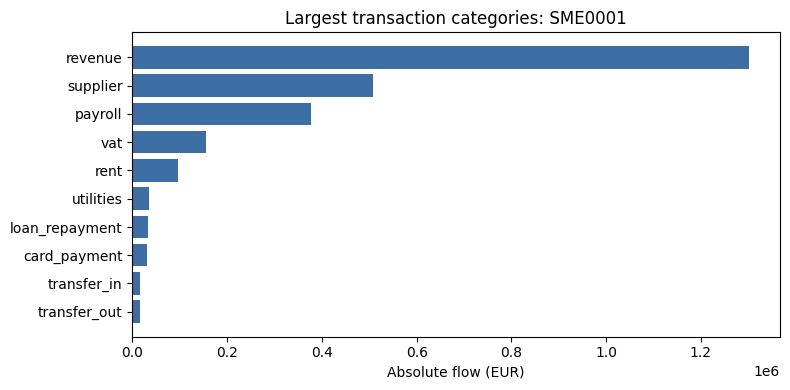

In [4]:
summary = categorizer.category_summary(labelled).head(10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(summary["category"], summary["abs_amount"], color="#3b6ea5")
ax.invert_yaxis()
ax.set_xlabel("Absolute flow (EUR)")
ax.set_title(f"Largest transaction categories: {example_id}")
plt.tight_layout()
plt.show()

## 3. Monthly cash-flow behaviour

Revenue is customer receipts only. Operating expenses exclude loan principal, which is tracked as debt service.

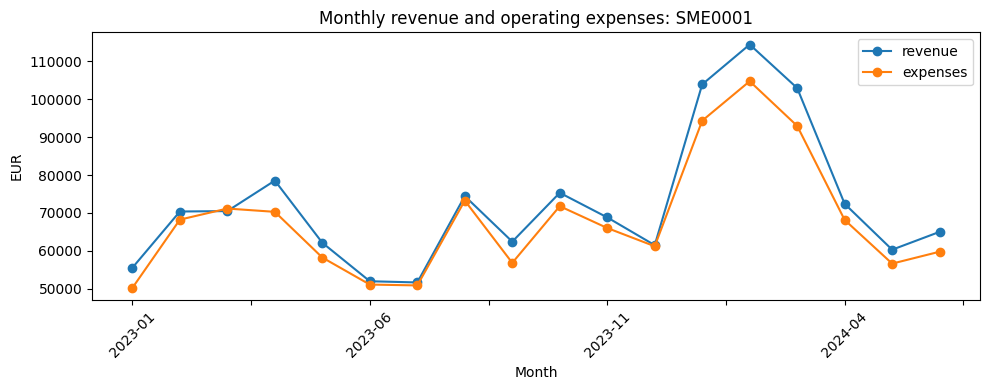

In [5]:
labelled["month"] = labelled["date"].dt.to_period("M").astype(str)
expense_mask = labelled["category"].isin(EXPENSE_CATEGORIES) & (labelled["amount"] < 0)
revenue_mask = (labelled["category"] == "revenue") & (labelled["amount"] > 0)

monthly = pd.DataFrame(
    {
        "inflow": labelled.loc[labelled["amount"] > 0].groupby("month")["amount"].sum(),
        "outflow": -labelled.loc[labelled["amount"] < 0].groupby("month")["amount"].sum(),
        "revenue": labelled.loc[revenue_mask].groupby("month")["amount"].sum(),
        "expenses": -labelled.loc[expense_mask].groupby("month")["amount"].sum(),
    }
).fillna(0.0)

fig, ax = plt.subplots(figsize=(10, 4))
monthly[["revenue", "expenses"]].plot(ax=ax, marker="o")
ax.set_title(f"Monthly revenue and operating expenses: {example_id}")
ax.set_xlabel("Month")
ax.set_ylabel("EUR")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 4. Build the full feature matrix

One row per borrower, 151 columns. The extractor uses a two-year window here so the full generated history is used.

In [6]:
extractor = CashFlowFeatureExtractor(config=FeatureConfig(window_days=18 * 31))
X = extractor.fit_transform(portfolio.transactions)
y = portfolio.labels.set_index("entity_id")["default_flag"].reindex(X.index)

print("Feature matrix:", X.shape)
print("Default rate:", round(float(y.mean()), 3))
print("All finite:", bool(X.notna().all().all()))
X[["revenue_total", "revenue_cv", "cash_buffer_months", "nsf_rate", "cashflow_health_score"]].describe().T

Feature matrix: (60, 151)
Default rate: 0.183
All finite: True


,count,mean,std,min,25%,50%,75%,max
revenue_total,60.0,3.240075e+06,1.805146e+06,810840.560000,2.064151e+06,2.838680e+06,3.950775e+06,8.091812e+06
revenue_cv,60.0,1.942387e-01,5.555404e-02,0.094286,1.499663e-01,1.988931e-01,2.358473e-01,3.353553e-01
cash_buffer_months,60.0,6.333175e-01,5.585626e-01,-0.906541,3.097870e-01,7.071102e-01,9.729144e-01,2.189900e+00
nsf_rate,60.0,7.251964e-04,1.305565e-03,0.000000,0.000000e+00,0.000000e+00,1.573005e-03,5.943536e-03
cashflow_health_score,60.0,7.705770e+01,1.304104e+01,40.756670,7.085974e+01,7.966125e+01,8.603416e+01,9.705878e+01


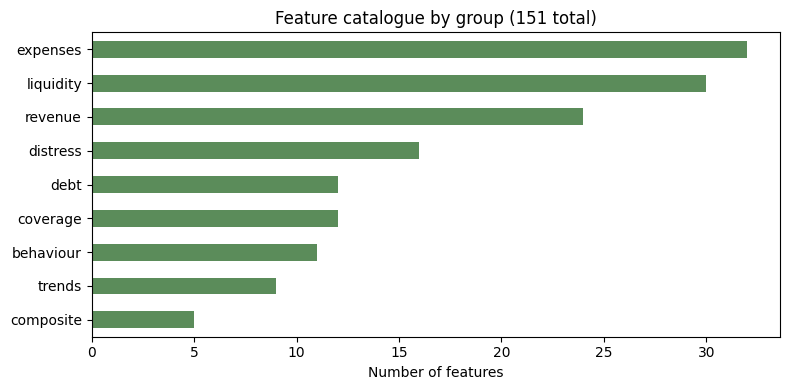

In [7]:
counts = pd.Series(feature_group_counts()).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 4))
counts.plot(kind="barh", ax=ax, color="#5b8c5a")
ax.set_xlabel("Number of features")
ax.set_title("Feature catalogue by group (151 total)")
plt.tight_layout()
plt.show()

## 5. Do the features separate defaults?

The synthetic labels are generated from post-ledger outcomes such as low balances, negative cash-flow months, failed payments and falling inflows. The features should recover that signal without seeing the latent stress variable.

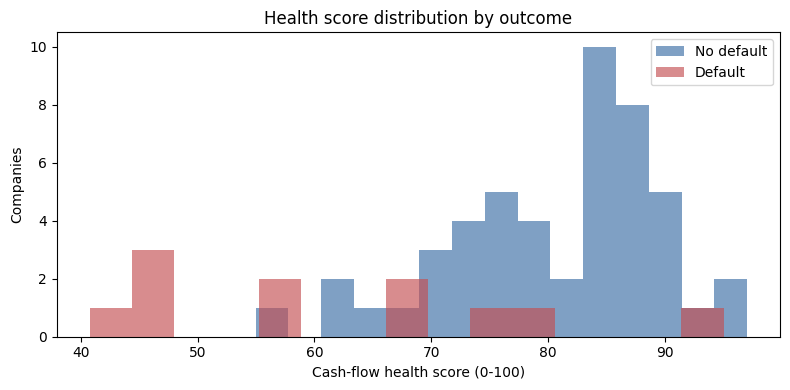

,mean_no_default,mean_default
revenue_cv,0.186,0.230
net_cash_flow_negative_ratio,0.187,0.566
overdraft_ratio,0.014,0.232
cashflow_health_score,80.482,61.802


In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(X.loc[y == 0, "cashflow_health_score"], bins=15, alpha=0.65, label="No default", color="#3b6ea5")
ax.hist(X.loc[y == 1, "cashflow_health_score"], bins=15, alpha=0.65, label="Default", color="#c44e52")
ax.set_xlabel("Cash-flow health score (0-100)")
ax.set_ylabel("Companies")
ax.set_title("Health score distribution by outcome")
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        "mean_no_default": X.loc[y == 0, ["revenue_cv", "net_cash_flow_negative_ratio", "overdraft_ratio", "cashflow_health_score"]].mean(),
        "mean_default": X.loc[y == 1, ["revenue_cv", "net_cash_flow_negative_ratio", "overdraft_ratio", "cashflow_health_score"]].mean(),
    }
).round(3)

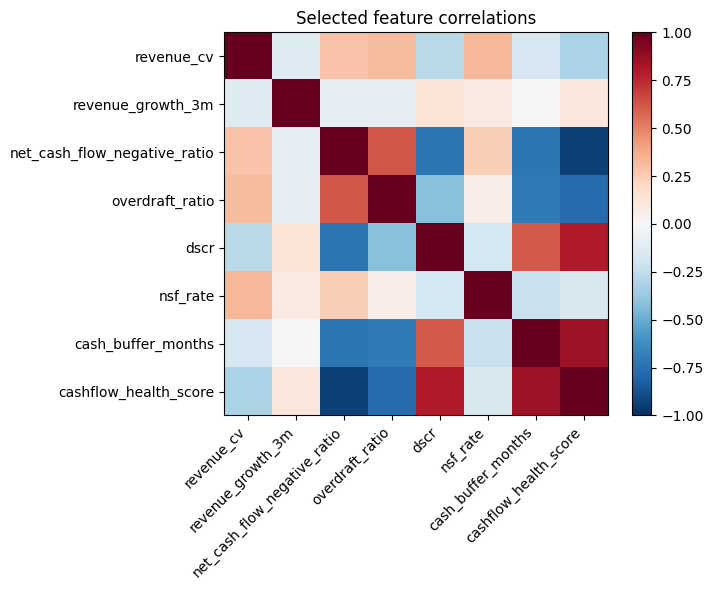

In [9]:
selected = [
    "revenue_cv",
    "revenue_growth_3m",
    "net_cash_flow_negative_ratio",
    "overdraft_ratio",
    "dscr",
    "nsf_rate",
    "cash_buffer_months",
    "cashflow_health_score",
]
corr = X[selected].corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(selected)), selected, rotation=45, ha="right")
ax.set_yticks(range(len(selected)), selected)
ax.set_title("Selected feature correlations")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 6. The feature dictionary

Every feature has a group, description, direction and formula. The catalogue is the single source of truth used by the extractor, docs and tests.

In [10]:
extractor.describe_features().query("group == 'liquidity'").head(10)[
    ["name", "description", "higher_is_better"]
]

,name,description,higher_is_better
68,balance_cv,Coefficient of variation of the running balance.,False
69,balance_drawdown_max,Largest peak-to-trough balance decline (0-1).,False
70,balance_last,Most recent running balance.,True
71,balance_last_90d_mean,Mean balance over the final 90 days.,True
72,balance_max,Maximum running balance.,None
73,balance_mean,Mean running balance.,True
74,balance_median,Median running balance.,True
75,balance_min,Minimum running balance.,True
76,balance_min_last_90d,Minimum balance over the final 90 days.,True
77,balance_p10,10th percentile of the running balance.,True


## Takeaways

* The categoriser turns localised narratives into consistent credit categories with an audit trail.
* The feature matrix is wide but documented, and every value is finite.
* Balance, negative-month, overdraft and health-score features separate outcomes in the synthetic benchmark.
* For production, pass a fixed `as_of` date and validate on out-of-time data.

Next: [02_limix_scoring.ipynb](02_limix_scoring.ipynb) for PD modelling and explanations.
